# 05 · Gate G2: score the test year (2019) once and freeze
Run this only after (a) notebook 04 froze the configurations and (b) the refit finished:
`python scripts/run_model.py refit --models all --h 15 60 --seeds`.
The refit already wrote the 2019 predictions (and refuses to overwrite them). This notebook only **scores** them.

In [1]:
import sys, os, json, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
from src import evaluate as ev, metrics as M, models as mo
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10, "axes.titleweight": "bold"})
def savefig(fig, name):
    fig.tight_layout(); fig.savefig(ev.FIGS / f"{name}.png", dpi=150); plt.show()
print("results folder:", ev.RESULTS, "| smoke mode:", mo.SMOKE, "| threads:", mo.N_JOBS)

results folder: C:\dev\traffic-prediction\results | smoke mode: False | threads: 11


## 0. Preconditions

In [2]:
assert (ev.RESULTS / "frozen_config.json").exists(), "freeze the configuration in notebook 04 first"
missing = [f"{n} h={h}" for n in mo.MODELS for h in ev.HORIZONS if not ev.pred_path("test", n, h).exists()]
assert not missing, f"2019 predictions missing (run the refit script): {missing}"
bb = {h: ev.best_baseline(ev.load_table(h, ["val"])) for h in ev.HORIZONS}        # chosen on VALIDATION
print("Best baseline (validation) per horizon:", bb)

Best baseline (validation) per horizon: {15: 'Persistence', 60: '4-week average'}


## 1. Headline table: pooled test metrics with 95 % confidence intervals
Intervals come from resampling whole **days** (1,000 times), because errors within a day are strongly correlated.
Skill = 1 - MAE(model) / MAE(best baseline). The three baselines are scored the same way.

In [3]:
assert (ev.RESULTS / "quality_rule.json").exists(), "run section 14 of notebook 01 first (the clean-row rule is frozen there)"
rows = []
for h in ev.HORIZONS:
    ref = ev.load_preds("test", "lgbm", h)                         # any model gives the same rows and baselines
    mk_all = np.ones(len(ref), bool)
    mk_clean = ev.clean_mask(ref)                                  # same fixed rule, applied to 2019 flow
    entries = {f"baseline: {k}": (ref[c] * ref["sc"]).to_numpy("float64") for k, c in ev.BASELINES.items()}
    for n in mo.MODELS:
        entries[mo.LABEL[n]] = ev.load_preds("test", n, h)["pred"].to_numpy("float64")
    base_all = (ref[ev.BASELINES[bb[h]]] * ref["sc"]).to_numpy("float64")
    for view, mk in (("all sensors", mk_all), ("clean rows", mk_clean)):
        day = ref["target_time"].dt.date.to_numpy()[mk]
        y = ref["y_raw"].to_numpy("float64")[mk]
        base = base_all[mk]
        for name, p in entries.items():
            p = p[mk]
            s = M.score(y, p); ci = M.day_block_bootstrap(day, y, p, base, n_boot=1000, seed=0)
            rows.append({"view": view, "rows_kept_%": mk.mean() * 100, "horizon_min": h, "model": name, "MAE": s["MAE"], "MAE_lo": ci["MAE"][0], "MAE_hi": ci["MAE"][1],
                         "RMSE": s["RMSE"], "WAPE_%": s["WAPE"] * 100, "Skill": M.skill(s["MAE"], M.mae(y, base)),
                         "Skill_lo": ci["Skill"][0], "Skill_hi": ci["Skill"][1]})
res_all = pd.DataFrame(rows)
res_all.to_csv(ev.FINAL / "headline_test_table.csv", index=False)
res = res_all[res_all["view"] == "clean rows"].copy()              # headline = clean rows; the all-sensor view is reported next to it
for h in ev.HORIZONS:
    for view in ("clean rows", "all sensors"):
        d = res_all[(res_all.horizon_min == h) & (res_all.view == view)]
        print(f"\n=== 2019, horizon {h} min, {view} ({d['rows_kept_%'].iloc[0]:.1f}% of rows; skill vs {bb[h]}) ===")
        display(d.drop(columns=["horizon_min", "view", "rows_kept_%"]).sort_values("MAE").round(3).reset_index(drop=True))


=== 2019, horizon 15 min, clean rows (87.2% of rows; skill vs Persistence) ===


,model,MAE,MAE_lo,MAE_hi,RMSE,WAPE_%,Skill,Skill_lo,Skill_hi
0,LightGBM,54.199,53.516,54.889,82.742,5.870,0.240,0.236,0.245
1,XGBoost,54.323,53.623,55.038,83.108,5.883,0.239,0.234,0.243
2,CatBoost,54.457,53.786,55.142,82.894,5.898,0.237,0.233,0.241
3,Random Forest,55.505,54.820,56.185,84.348,6.011,0.222,0.217,0.227
4,Gradient Boosting,56.517,55.849,57.193,85.150,6.121,0.208,0.203,0.213
5,AdaBoost,57.177,56.508,57.847,86.018,6.192,0.199,0.194,0.204
6,Decision Tree,58.352,57.670,59.022,87.646,6.320,0.182,0.177,0.187
7,PCA + Ridge,61.174,60.446,61.920,90.635,6.625,0.143,0.136,0.149
8,Ridge,61.174,60.446,61.920,90.635,6.625,0.143,0.136,0.149
9,baseline: Persistence,71.350,70.498,72.150,104.535,7.727,0.000,0.000,0.000



=== 2019, horizon 15 min, all sensors (100.0% of rows; skill vs Persistence) ===


,model,MAE,MAE_lo,MAE_hi,RMSE,WAPE_%,Skill,Skill_lo,Skill_hi
0,LightGBM,48.628,47.983,49.280,77.504,5.307,0.267,0.263,0.271
1,XGBoost,48.734,48.078,49.394,77.846,5.318,0.266,0.262,0.270
2,CatBoost,48.955,48.333,49.610,77.657,5.343,0.262,0.259,0.266
3,Random Forest,49.552,48.943,50.189,78.952,5.408,0.253,0.249,0.258
4,Gradient Boosting,50.783,50.169,51.421,79.789,5.542,0.235,0.230,0.239
5,AdaBoost,51.123,50.516,51.757,80.550,5.579,0.230,0.225,0.235
6,Decision Tree,52.497,51.881,53.125,82.163,5.729,0.209,0.204,0.214
7,PCA + Ridge,55.981,55.319,56.687,85.276,6.109,0.157,0.150,0.163
8,Ridge,55.981,55.319,56.687,85.276,6.109,0.157,0.150,0.163
9,baseline: Persistence,66.379,65.570,67.119,99.011,7.244,0.000,0.000,0.000



=== 2019, horizon 60 min, clean rows (87.2% of rows; skill vs 4-week average) ===


,model,MAE,MAE_lo,MAE_hi,RMSE,WAPE_%,Skill,Skill_lo,Skill_hi
0,LightGBM,67.241,66.270,68.193,103.828,7.282,0.237,0.212,0.262
1,XGBoost,67.375,66.405,68.356,104.325,7.296,0.235,0.210,0.261
2,CatBoost,67.552,66.543,68.542,103.937,7.315,0.233,0.208,0.259
3,Random Forest,69.306,68.227,70.370,106.328,7.505,0.213,0.190,0.237
4,Gradient Boosting,70.949,69.880,72.002,107.606,7.683,0.195,0.171,0.219
5,AdaBoost,73.009,71.814,74.134,110.635,7.906,0.171,0.148,0.196
6,Decision Tree,74.303,73.170,75.469,113.294,8.046,0.157,0.133,0.181
7,Ridge,81.595,80.030,83.232,121.288,8.836,0.074,0.053,0.094
8,PCA + Ridge,81.595,80.030,83.232,121.288,8.836,0.074,0.053,0.094
9,baseline: 4-week average,88.097,84.943,91.495,142.367,9.540,0.000,0.000,0.000



=== 2019, horizon 60 min, all sensors (100.0% of rows; skill vs 4-week average) ===


,model,MAE,MAE_lo,MAE_hi,RMSE,WAPE_%,Skill,Skill_lo,Skill_hi
0,LightGBM,61.152,60.273,62.015,97.570,6.673,0.220,0.195,0.246
1,XGBoost,61.290,60.399,62.176,98.053,6.688,0.219,0.194,0.244
2,CatBoost,61.577,60.668,62.495,97.729,6.719,0.215,0.190,0.240
3,Random Forest,62.348,61.364,63.292,99.772,6.804,0.205,0.182,0.228
4,Gradient Boosting,64.307,63.339,65.253,101.170,7.017,0.180,0.157,0.203
5,AdaBoost,65.810,64.758,66.802,103.953,7.181,0.161,0.138,0.185
6,Decision Tree,67.121,66.061,68.157,106.515,7.324,0.144,0.121,0.169
7,Ridge,75.258,73.830,76.717,114.643,8.212,0.040,0.019,0.061
8,PCA + Ridge,75.258,73.830,76.717,114.643,8.212,0.040,0.019,0.061
9,baseline: 4-week average,78.434,75.613,81.430,134.614,8.559,0.000,0.000,0.000


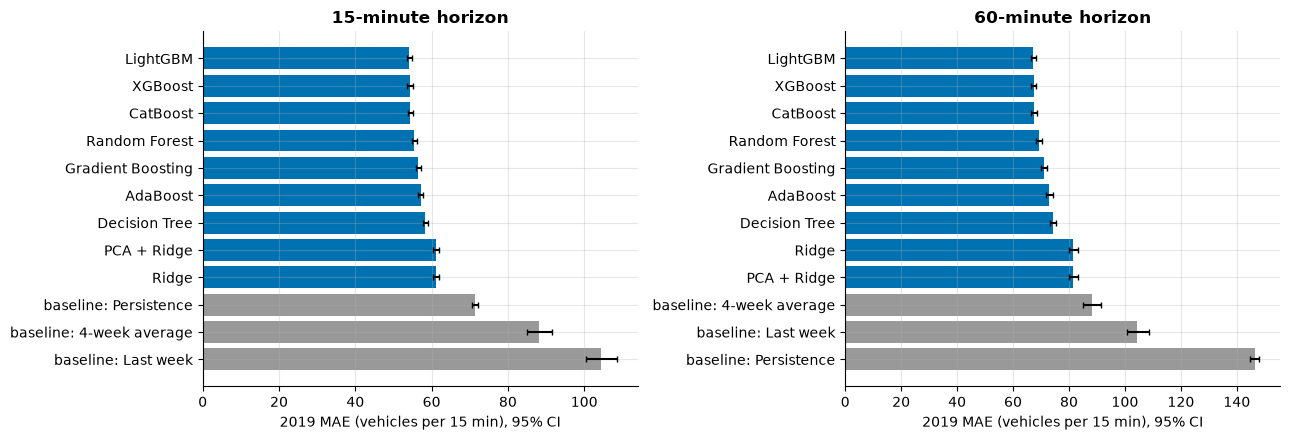

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, h in zip(axes, ev.HORIZONS):
    d = res[res.horizon_min == h].sort_values("MAE", ascending=False)
    col = ["#999999" if m.startswith("baseline") else "#0072B2" for m in d["model"]]
    ax.barh(d["model"], d["MAE"], xerr=[d["MAE"] - d["MAE_lo"], d["MAE_hi"] - d["MAE"]], color=col, capsize=2)
    ax.set_xlabel("2019 MAE (vehicles per 15 min), 95% CI"); ax.set_title(f"{h}-minute horizon")
savefig(fig, "test_headline")

## 2. Warm vs cold sensors (do models generalise to sensors never seen in training?)

In [5]:
rows = []
for h in ev.HORIZONS:
    for n in mo.MODELS:
        d = ev.load_preds("test", n, h)
        for role, g in d.groupby("role"):
            rows.append({"horizon_min": h, "model": mo.LABEL[n], "role": role, "MAE": M.mae(g["y_raw"], g["pred"]), "WAPE_%": M.wape(g["y_raw"], g["pred"]) * 100})
wc = pd.DataFrame(rows)
wc.to_csv(ev.FINAL / "test_warm_vs_cold.csv", index=False)
piv = wc.pivot_table(index=["horizon_min", "model"], columns="role", values="WAPE_%")
piv["cold_minus_warm_pts"] = piv["cold"] - piv["warm"]
display(piv.round(2))

role                           cold  warm  cold_minus_warm_pts
horizon_min model                                             
15          AdaBoost           6.10  5.45                 0.65
            CatBoost           5.83  5.22                 0.61
            Decision Tree      6.23  5.61                 0.62
            Gradient Boosting  6.02  5.42                 0.60
            LightGBM           5.80  5.19                 0.61
            PCA + Ridge        6.59  5.99                 0.60
            Random Forest      5.91  5.29                 0.62
            Ridge              6.59  5.99                 0.60
            XGBoost            5.81  5.20                 0.61
60          AdaBoost           7.67  7.06                 0.61
            CatBoost           7.22  6.60                 0.62
            Decision Tree      7.82  7.20                 0.61
            Gradient Boosting  7.48  6.90                 0.58
            LightGBM           7.19  6.55                 0.64
            PCA + Ridge        8.70  8.09                 0.61
            Random Forest      7.28  6.69                 0.59
            Ridge              8.70  8.09                 0.61
            XGBoost            7.21  6.56                 0.65

## 3. By quarter of 2019 and by corridor (best 3 models at each horizon)

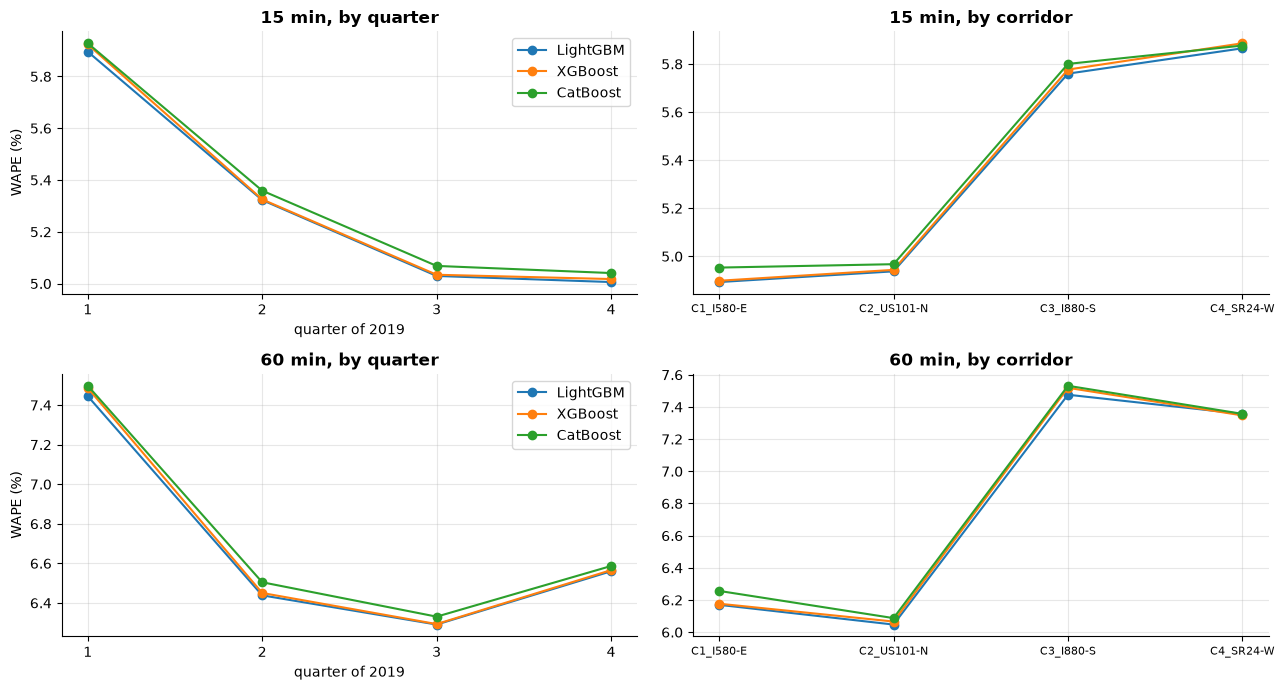

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for r, h in enumerate(ev.HORIZONS):
    top3 = res[(res.horizon_min == h) & (~res.model.str.startswith("baseline"))].nsmallest(3, "MAE")["model"].tolist()
    inv = {v: k for k, v in mo.LABEL.items()}
    for n in top3:
        d = ev.load_preds("test", inv[n], h)
        q = d.groupby(d["target_time"].dt.quarter).apply(lambda x: M.wape(x["y_raw"], x["pred"]) * 100)
        c = d.groupby("corridor").apply(lambda x: M.wape(x["y_raw"], x["pred"]) * 100)
        axes[r, 0].plot(q.index, q.values, "o-", label=n); axes[r, 1].plot(range(len(c)), c.values, "o-", label=n)
    axes[r, 0].set_xticks([1, 2, 3, 4]); axes[r, 0].set_xlabel("quarter of 2019"); axes[r, 0].set_ylabel("WAPE (%)"); axes[r, 0].set_title(f"{h} min, by quarter"); axes[r, 0].legend()
    axes[r, 1].set_xticks(range(len(c))); axes[r, 1].set_xticklabels(c.index, fontsize=8); axes[r, 1].set_title(f"{h} min, by corridor")
savefig(fig, "test_quarter_corridor")

## 4. Per-sensor spread (is the average hiding bad sensors?)

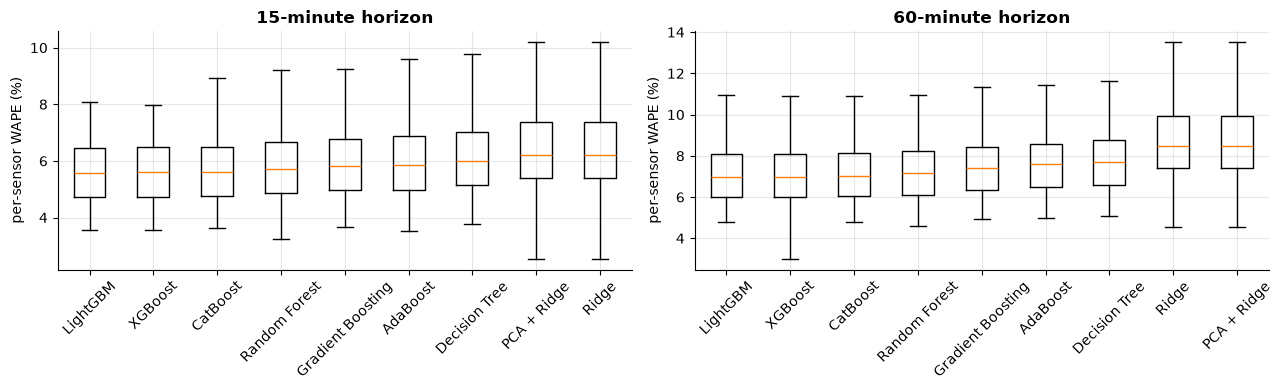

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, h in zip(axes, ev.HORIZONS):
    order = res[(res.horizon_min == h) & (~res.model.str.startswith("baseline"))].sort_values("MAE")["model"].tolist()
    inv = {v: k for k, v in mo.LABEL.items()}
    data = []
    for n in order:
        d = ev.load_preds("test", inv[n], h)
        data.append(d.groupby("ID2").apply(lambda x: M.wape(x["y_raw"], x["pred"]) * 100).to_numpy())
    ax.boxplot(data, showfliers=False); ax.set_xticks(range(1, len(order) + 1)); ax.set_xticklabels(order); ax.tick_params(axis="x", rotation=45)
    ax.set_ylabel("per-sensor WAPE (%)"); ax.set_title(f"{h}-minute horizon")
savefig(fig, "test_per_sensor")

## 5. LightGBM seed stability and compute cost

In [8]:
rows = []
for h in ev.HORIZONS:
    maes = []
    for tag in ["", "_seed43", "_seed44"]:
        if ev.pred_path("test", "lgbm", h, tag).exists():
            d = ev.load_preds("test", "lgbm", h, tag); maes.append(M.mae(d["y_raw"], d["pred"]))
    rows.append({"horizon_min": h, "seeds": len(maes), "MAE_mean": np.mean(maes), "MAE_sd": np.std(maes, ddof=1) if len(maes) > 1 else np.nan})
display(pd.DataFrame(rows).round(4))
cost = pd.DataFrame([json.loads(f.read_text()) for f in sorted(ev.FINAL.glob("cost_*_h*.json")) if "seed" not in f.name])
cost["model"] = cost["model"].map(mo.LABEL)
cost = cost[["model", "h", "fit_rows", "n_estimators", "fit_s", "predict_s_per_100k", "model_MB"]].sort_values(["h", "fit_s"])
cost.to_csv(ev.FINAL / "cost_table.csv", index=False)
display(cost.round(2))

,horizon_min,seeds,MAE_mean,MAE_sd
0,15,3,48.6160,0.0186
1,60,3,61.1673,0.0156


,model,h,fit_rows,n_estimators,fit_s,predict_s_per_100k,model_MB
10,PCA + Ridge,15,1343584,NaN,1.29,0.03,0.01
14,Ridge,15,1343584,NaN,5.20,0.02,0.00
4,Decision Tree,15,1343584,NaN,44.39,0.02,0.76
8,LightGBM,15,1343584,1414.0,147.15,5.07,17.40
16,XGBoost,15,1343584,1943.0,189.16,1.41,29.42
12,Random Forest,15,1343584,NaN,273.05,0.61,292.15
2,CatBoost,15,1343584,2000.0,640.39,0.12,8.47
6,Gradient Boosting,15,1343584,299.0,2480.38,0.68,1.03
0,AdaBoost,15,1343584,NaN,7249.88,10.66,34.11
11,PCA + Ridge,60,1343576,NaN,1.36,0.03,0.01


## 6. Freeze (Gate G2)
Stores a fingerprint of every 2019 prediction file and the headline table, so you can prove later that nothing
changed after the test year was scored.

In [9]:
import hashlib, datetime
def sha(p): return hashlib.sha256(Path(p).read_bytes()).hexdigest()[:16]
frz = {"frozen_at": datetime.datetime.now().isoformat(timespec="seconds"),
       "best_baseline_by_validation": {str(h): b for h, b in bb.items()},
       "test_prediction_files": {f.name: sha(f) for f in sorted(ev.PREDS.glob("test_*.parquet"))},
       "frozen_config": sha(ev.RESULTS / "frozen_config.json"), "headline_table": sha(ev.FINAL / "headline_test_table.csv")}
(ev.RESULTS / "FROZEN.json").write_text(json.dumps(frz, indent=2))
print("GATE G2: results frozen at", frz["frozen_at"], "-", len(frz["test_prediction_files"]), "prediction files fingerprinted")

GATE G2: results frozen at 2026-11-23T19:01:58 - 22 prediction files fingerprinted
